# MSENet baseline vs. LayerNorm vs. learnable temperature — four-way comparison

**Run on Kaggle:** Accelerator = GPU (T4), Internet = On, then **Run All**. Nothing needs to be uploaded or edited.

| # | Variant | Change relative to `baseline.ipynb` |
|---|---------|-------------------------------------|
| 1 | Baseline | none (flags off, identical graph/optimizer/loop) |
| 2 | LayerNorm only | `nn.LayerNorm(C_stage)` on each stage's pooled embedding (after self-attention + GAP), before prototypes and Euclidean distance. No L2 normalisation |
| 3 | Learnable temperature only | `logits = -weighted_distance / softplus(raw)`; `raw` initialised so temperature = 1.0 |
| 4 | LayerNorm + temperature | exactly 2 and 3 combined |

**Protocol (identical for all four):** MiniImageNet, 5-way 5-shot only, 10 epochs x 360 training episodes (30-way, 5-shot, 15-query), the same 600 validation and 600 test episodes (generated once and frozen), best-validation checkpoint kept in memory (no `.pth` files written), per-variant reseeding.

**Expected runtime:** roughly 1.1 h per variant on a T4, so about 4.5 h in total. Everything is saved to `/kaggle/working/msenet_comparison_results/` and zipped at the very end.

In [1]:
!pip -q install easyfsl gdown

## 1. Imports, warnings and configuration

In [2]:
import os, sys, time, random, json, copy, gc, math, hashlib, zipfile, base64, platform, subprocess, tarfile, shutil, types, warnings
from pathlib import Path
from collections import defaultdict
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch import nn, optim
from torch.utils.data import DataLoader, Sampler
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torchvision.models import resnet18, ResNet18_Weights
from torchvision.models.feature_extraction import create_feature_extractor, get_graph_node_names
from easyfsl.samplers import TaskSampler
from tqdm.auto import tqdm
import multiprocessing
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, FileLink, Javascript

# Silence non-critical warnings only; exceptions are never suppressed.
for _cat in (FutureWarning, DeprecationWarning, UserWarning):
    warnings.filterwarnings("ignore", category=_cat)
pd.set_option("display.max_columns", None, "display.width", 250)
print("Imports OK | torch", torch.__version__)

Imports OK | torch 2.11.0+cu128


In [3]:
# ======================= Baseline configuration (copied unchanged from baseline.ipynb) =======================
# Force 'spawn' start method to eliminate Python 3.13 multiprocessing cleanup warnings
try:
    multiprocessing.set_start_method('spawn', force=True)
except RuntimeError:
    pass

SEED = 42
def set_all_seeds(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_all_seeds(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
if device.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
else:
    raise RuntimeError("No GPU detected. In Kaggle: Settings -> Accelerator -> GPU T4 (and Internet -> On), then Run All again.")

ROOT_DIRECTORY = "/kaggle/working/miniimagenet"

IMAGE_SIZE = 84
MAX_EPOCHS = 10
N_TRAINING_EPISODES = 360
N_VALIDATION_TASKS = 600
N_TEST_TASKS = 600
TRAIN_WAY = 30
TEST_WAY = 5
SHOT = 5          # 5-way 5-shot ONLY
QUERY = 15
FEATURE_CHUNK_SIZE = 600
ATTENTION_CHUNK_SIZE = 600

DISTANCE_METRIC = 'euclidean'
COSINE_TEMP = 10.0           # baseline's (unused with euclidean) parameter; kept untouched
USE_AMP = True

STAGE_NODES   = ('maxpool', 'layer1', 'layer2', 'layer3', 'layer4')
STAGE_WEIGHTS = (1.0, 1.1, 1.2, 1.3, 1.4)

USE_IMAGENET_PRETRAINED = True
NUM_WORKERS = 0

# Training hyper-parameters (from the baseline training cell)
gamma_init = 0.2
weights_lr = 0.005
backbone_lr = 1e-4

_norm = transforms.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    _norm,
])
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    _norm,
])

assert DISTANCE_METRIC == 'euclidean', "This study keeps the baseline's Euclidean distance."

# ======================= Experiment configuration (new) =======================
VARIANTS = [
    dict(key='baseline',    short='Baseline',    label='1. Baseline (unchanged)',        use_layernorm=False, use_temperature=False),
    dict(key='layernorm',   short='LayerNorm',   label='2. LayerNorm only',              use_layernorm=True,  use_temperature=False),
    dict(key='temperature', short='Temperature', label='3. Learnable temperature only',  use_layernorm=False, use_temperature=True),
    dict(key='ln_temp',     short='LN + Temp',   label='4. LayerNorm + temperature',     use_layernorm=True,  use_temperature=True),
]
TEMPERATURE_INIT = 1.0
TEMPERATURE_LR = weights_lr      # 0.005, same group lr as stage weights / gammas
# LayerNorm parameters stay in the baseline "regular" parameter group, i.e. lr = backbone_lr = 1e-4.
LN_SHARED_ACROSS_SUPPORT_QUERY = True   # one nn.LayerNorm per stage, applied independently (per sample) to support and query embeddings.
                                        # Set False to give support and query their own separate LayerNorm modules.
EVAL_EPISODE_SEED = 2026     # val episodes use this seed, test episodes use seed+1; frozen and shared by all variants
INFERENCE_WARMUP_EPISODES = 10
RESUME_PARTIAL = False       # True: reuse per-variant JSON files from an earlier run in the same session

RESULTS_DIR = Path('/kaggle/working/msenet_comparison_results')
PLOTS_DIR = RESULTS_DIR / 'plots'
PARTIAL_DIR = RESULTS_DIR / 'partial'      # not included in the ZIP
for d in (RESULTS_DIR, PLOTS_DIR, PARTIAL_DIR):
    d.mkdir(parents=True, exist_ok=True)
print('Configuration ready. Results ->', RESULTS_DIR)

Device: cuda
GPU: Tesla T4
Configuration ready. Results -> /kaggle/working/msenet_comparison_results


## 2. Dataset: automatic download + extraction (MiniImageNet from Google Drive)

In [4]:
DRIVE_FOLDER = "https://drive.google.com/drive/folders/17a09kkqVivZQFggCw9I_YboJ23tcexNM"
DOWNLOAD_DIR = Path("/kaggle/working/miniimagenet_archives")
DATA_DIR = Path(ROOT_DIRECTORY)
SPLITS = ("train", "val", "test")
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)

def _has_images(d):
    d = Path(d)
    if not d.exists():
        return False
    for p in d.rglob('*'):
        if p.suffix.lower() in IMG_EXT:
            return True
    return False

def run_gdown():
    try:
        return subprocess.run(["gdown", "--folder", DRIVE_FOLDER, "-O", str(DOWNLOAD_DIR)], check=False).returncode
    except FileNotFoundError:
        import gdown
        gdown.download_folder(url=DRIVE_FOLDER, output=str(DOWNLOAD_DIR), quiet=False, use_cookies=False)
        return 0

if all(_has_images(DATA_DIR / s) for s in SPLITS):
    print("Dataset already extracted - skipping download.")
else:
    t0 = time.time()
    found = {}
    for attempt in range(1, 4):
        print(f"[download] attempt {attempt}/3 ...")
        rc = run_gdown()
        print("Download command exit code:", rc)
        found = {s: list(DOWNLOAD_DIR.rglob(f"{s}.tar")) for s in SPLITS}
        if all(found.values()):
            break
        print("Missing archives:", [s for s, v in found.items() if not v], "- retrying in 15 s")
        time.sleep(15)
    missing = [s for s, v in found.items() if not v]
    if missing:
        raise FileNotFoundError(f"{missing} .tar not found after 3 attempts. Check that Internet is ON in the Kaggle settings, "
                                "that the Drive folder is still public, and that the Drive download quota is not exceeded.")
    print("Downloaded files:")
    for p in DOWNLOAD_DIR.rglob("*"):
        if p.is_file():
            print(f"  {p.name}: {p.stat().st_size / 1e6:.1f} MB")

    for split in tqdm(SPLITS, desc="Extracting archives"):
        archive = found[split][0]
        out_dir = DATA_DIR / split
        out_dir.mkdir(parents=True, exist_ok=True)
        print(f"Extracting {archive.name} -> {out_dir} ...")
        with tarfile.open(archive, "r:*") as tar:
            try:
                tar.extractall(out_dir, filter="data")
            except TypeError:           # older Python without the extraction filter argument
                tar.extractall(out_dir)
    print(f"Download + extraction finished in {(time.time() - t0) / 60:.1f} min")

for junk in DATA_DIR.rglob("__MACOSX"):
    shutil.rmtree(junk, ignore_errors=True)

def resolve_class_root(split_dir):
    # Descend through single wrapper folders (e.g. train/train/<classes>) until the class folders are reached.
    p = Path(split_dir)
    while True:
        entries = [e for e in p.iterdir() if not e.name.startswith('.')]
        subdirs = [e for e in entries if e.is_dir()]
        files = [e for e in entries if e.is_file()]
        if len(subdirs) == 1 and not files:
            p = subdirs[0]
            continue
        return p

TRAIN_DIR = str(resolve_class_root(DATA_DIR / "train"))
VAL_DIR   = str(resolve_class_root(DATA_DIR / "val"))
TEST_DIR  = str(resolve_class_root(DATA_DIR / "test"))
for split, path in [("train", TRAIN_DIR), ("val", VAL_DIR), ("test", TEST_DIR)]:
    p = Path(path)
    classes = [d for d in p.iterdir() if d.is_dir()]
    print(f"{split}: {path} | class folders={len(classes)} | examples={[d.name for d in classes[:3]]}")

[download] attempt 1/3 ...


Retrieving folder contents
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1yKyKgxcnGMIAnA_6Vr2ilbpHMc9COg-v
To: /kaggle/working/miniimagenet_archives/test.tar
 11%|█         | 4.19M/39.2M [00:00<00:00, 41.7MB/s]

Processing file 1yKyKgxcnGMIAnA_6Vr2ilbpHMc9COg-v test.tar
Processing file 107FTosYIeBn5QbynR46YG91nHcJ70whs train.tar
Processing file 1hSMUMj5IRpf-nQs1OwgiQLmGZCN0KDWl val.tar


100%|██████████| 39.2M/39.2M [00:00<00:00, 167MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=107FTosYIeBn5QbynR46YG91nHcJ70whs
From (redirected): https://drive.google.com/uc?id=107FTosYIeBn5QbynR46YG91nHcJ70whs&confirm=t&uuid=b92b932e-fff1-4f97-ab87-116f0b5d6bb7
To: /kaggle/working/miniimagenet_archives/train.tar
100%|██████████| 126M/126M [00:01<00:00, 88.4MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1hSMUMj5IRpf-nQs1OwgiQLmGZCN0KDWl
From (redirected): https://drive.google.com/uc?id=1hSMUMj5IRpf-nQs1OwgiQLmGZCN0KDWl&confirm=t&uuid=e9b553ab-8548-462b-bbaa-2ca05d3c3a83
To: /kaggle/working/miniimagenet_archives/val.tar
 46%|████▌     | 14.2M/30.8M [00:00<00:00, 141MB/s]

Download command exit code: 0
Downloaded files:
  val.tar: 30.8 MB
  test.tar: 39.2 MB
  train.tar: 125.9 MB


100%|██████████| 30.8M/30.8M [00:00<00:00, 138MB/s]
Download completed


Extracting archives:   0%|          | 0/3 [00:00<?, ?it/s]

Extracting train.tar -> /kaggle/working/miniimagenet/train ...
Extracting val.tar -> /kaggle/working/miniimagenet/val ...
Extracting test.tar -> /kaggle/working/miniimagenet/test ...
Download + extraction finished in 1.3 min
train: /kaggle/working/miniimagenet/train/train | class folders=64 | examples=['n03476684', 'n02120079', 'n02091831']
val: /kaggle/working/miniimagenet/val/val | class folders=16 | examples=['n03417042', 'n02114548', 'n02174001']
test: /kaggle/working/miniimagenet/test/test | class folders=20 | examples=['n02871525', 'n02099601', 'n01930112']


## 3. Model (baseline code, plus two opt-in switches that are OFF by default)

In [5]:
# Multi-scale attention model (baseline code; additions are marked NEW and are disabled by default)
class Self_Attn(nn.Module):
    def __init__(self, in_dim):
        super().__init__()
        if in_dim < 8:
            raise ValueError(f'in_dim must be >= 8, got {in_dim}')
        self.query_conv = nn.Conv2d(in_dim, in_dim // 8, kernel_size=1)
        self.key_conv = nn.Conv2d(in_dim, in_dim // 8, kernel_size=1)
        self.value_conv = nn.Conv2d(in_dim, in_dim, kernel_size=1)

    def forward(self, x, gamma):
        b, c, h, w = x.shape
        n = h * w
        q = self.query_conv(x).reshape(b, -1, n).transpose(1, 2)  # B,N,C/8
        k = self.key_conv(x).reshape(b, -1, n)                   # B,C/8,N
        attention = torch.softmax(torch.bmm(q, k), dim=-1)        # B,N,N
        v = self.value_conv(x).reshape(b, c, n)                   # B,C,N
        out = torch.bmm(v, attention.transpose(1, 2)).reshape(b, c, h, w)
        return gamma * out + x

def inverse_softplus(y):
    # softplus(inverse_softplus(y)) == y   (used to start the temperature at exactly TEMPERATURE_INIT)
    return math.log(math.expm1(y))

class PrototypicalNetworks(nn.Module):
    def __init__(self, backbone, image_size, stage_nodes=STAGE_NODES, weight=STAGE_WEIGHTS,
                 weightlearnable=True, gammalearnable=True, gamma1=0.2, gamma2=0.2,
                 feature_chunk_size=600, attention_chunk_size=600,
                 distance_metric='cosine', cosine_temp=10.0,
                 use_layernorm=False, ln_shared=True,            # NEW
                 use_temperature=False, temperature_init=1.0):   # NEW
        super().__init__()
        if len(weight) != len(stage_nodes):
            raise ValueError(f'{len(weight)} weights given for {len(stage_nodes)} stages.')
        self.weightlearnable = weightlearnable
        self.gammalearnable = gammalearnable
        self.feature_chunk_size = feature_chunk_size
        self.attention_chunk_size = attention_chunk_size
        self.n_stages = len(stage_nodes)
        self.distance_metric = distance_metric

        # Learnable temperature scalar for cosine distance scaling (baseline parameter, unused with euclidean)
        self.cosine_temp = nn.Parameter(torch.tensor(float(cosine_temp)), requires_grad=True)

        self.stage_weights = nn.Parameter(torch.tensor(list(weight), dtype=torch.float32),
                                          requires_grad=weightlearnable)
        self.gamma1_l = nn.Parameter(torch.tensor(float(gamma1)), requires_grad=gammalearnable)
        self.gamma2_l = nn.Parameter(torch.tensor(float(gamma2)), requires_grad=gammalearnable)

        graph_nodes, _ = get_graph_node_names(backbone)
        return_nodes = {}
        for i, name in enumerate(stage_nodes):
            matches = [n for n in graph_nodes if n == name or n.startswith(name + '.')]
            if not matches:
                raise ValueError(f'Stage {name!r} not found in backbone graph.')
            return_nodes[matches[-1]] = f'stage_{i}'
        print('Stage nodes:', return_nodes)

        self.feature_extractor = create_feature_extractor(backbone, return_nodes=return_nodes)

        was_training = self.feature_extractor.training
        self.feature_extractor.eval()
        with torch.no_grad():
            dummy = self.feature_extractor(torch.zeros(1, 3, image_size, image_size))
        self.feature_extractor.train(was_training)
        channels = [dummy[f'stage_{i}'].shape[1] for i in range(self.n_stages)]
        print('Selected feature channels:', channels,
              '| spatial sizes:', [tuple(dummy[f'stage_{i}'].shape[2:]) for i in range(self.n_stages)])

        self.attention_modules = nn.ModuleList([Self_Attn(c) for c in channels])
        self.global_avg_pool = nn.AdaptiveAvgPool2d(1)

        # ---------------- NEW (opt-in; with both flags False the module is identical to the baseline) ----------------
        self.use_layernorm = use_layernorm
        self.ln_shared = ln_shared
        if use_layernorm:
            # one LayerNorm per stage over that stage's channel dimension; default elementwise affine, no L2 normalisation
            self.stage_norms_support = nn.ModuleList([nn.LayerNorm(c) for c in channels])
            if not ln_shared:
                self.stage_norms_query = nn.ModuleList([nn.LayerNorm(c) for c in channels])
        self.use_temperature = use_temperature
        if use_temperature:
            if temperature_init <= 0:
                raise ValueError('temperature_init must be > 0')
            self.temperature_raw = nn.Parameter(torch.tensor(inverse_softplus(float(temperature_init)), dtype=torch.float32))

    def temperature(self):
        return F.softplus(self.temperature_raw) if self.use_temperature else None

    def _extract_in_chunks(self, images):
        # Fast path: if batch fits in chunk_size, skip Python loop & dict rebuilding!
        if images.size(0) <= self.feature_chunk_size:
            return self.feature_extractor(images)
        collected = None
        for chunk in images.split(self.feature_chunk_size, dim=0):
            feats = self.feature_extractor(chunk)
            if collected is None:
                collected = {key: [value] for key, value in feats.items()}
            else:
                for key, value in feats.items(): collected[key].append(value)
        return {key: torch.cat(values, dim=0) for key, values in collected.items()}

    def _attend_and_pool(self, features, stage_idx, gamma):
        module = self.attention_modules[stage_idx]
        # Fast path: skip chunking loop when batch size <= attention_chunk_size
        if features.size(0) <= self.attention_chunk_size:
            return self.global_avg_pool(module(features, gamma)).flatten(1)
        pooled = []
        for chunk in features.split(self.attention_chunk_size, dim=0):
            pooled.append(self.global_avg_pool(module(chunk, gamma)).flatten(1))
        return torch.cat(pooled, dim=0)

    def _stage_distance(self, support_features, query_features, support_labels, stage_idx):
        z_support = self._attend_and_pool(support_features, stage_idx, self.gamma1_l)
        z_query = self._attend_and_pool(query_features, stage_idx, self.gamma2_l)

        # NEW: per-stage LayerNorm on the pooled embeddings, before prototype computation and distance
        if self.use_layernorm:
            z_support = self.stage_norms_support[stage_idx](z_support)
            q_norms = self.stage_norms_support if self.ln_shared else self.stage_norms_query
            z_query = q_norms[stage_idx](z_query)

        labels = torch.unique(support_labels, sorted=True)
        prototypes = torch.stack([z_support[support_labels == label].mean(0) for label in labels])

        if self.distance_metric == 'euclidean':
            return torch.cdist(z_query, prototypes, p=2)

        elif self.distance_metric == 'cosine':
            z_q_norm = nn.functional.normalize(z_query, p=2, dim=-1)
            proto_norm = nn.functional.normalize(prototypes, p=2, dim=-1)
            cos_sim = torch.mm(z_q_norm, proto_norm.t())
            return self.cosine_temp * (1.0 - cos_sim)

        elif self.distance_metric == 'hybrid':
            euc_dist = torch.cdist(z_query, prototypes, p=2)
            z_q_norm = nn.functional.normalize(z_query, p=2, dim=-1)
            proto_norm = nn.functional.normalize(prototypes, p=2, dim=-1)
            cos_dist = self.cosine_temp * (1.0 - torch.mm(z_q_norm, proto_norm.t()))
            return 0.5 * euc_dist + 0.5 * cos_dist
        else:
            raise ValueError(f"Unknown distance_metric: {self.distance_metric}")

    def forward(self, support_images, support_labels, query_images):
        support_feats = self._extract_in_chunks(support_images)
        query_feats = self._extract_in_chunks(query_images)
        distances = torch.stack([
            self._stage_distance(support_feats[f'stage_{i}'], query_feats[f'stage_{i}'], support_labels, i)
            for i in range(self.n_stages)
        ])
        logits = -(self.stage_weights.view(-1, 1, 1) * distances).sum(dim=0)
        if self.use_temperature:                      # NEW: logits = -weighted_distance / temperature
            logits = logits / F.softplus(self.temperature_raw)
        return logits

print('Model class defined.')

Model class defined.


## 4. Sampler patch, datasets and frozen evaluation episodes

In [6]:
# Fast episode sampler compatibility patch for EasyFSL / newer PyTorch (baseline code, unchanged)
def _patched_task_sampler_init(self, dataset, n_way, n_shot, n_query, n_tasks):
    Sampler.__init__(self)
    self.n_way, self.n_shot, self.n_query, self.n_tasks = n_way, n_shot, n_query, n_tasks
    self.items_per_label = defaultdict(list)
    for item, label in enumerate(dataset.get_labels()):
        self.items_per_label[int(label)].append(item)
    if len(self.items_per_label) < n_way:
        raise ValueError(f'Requested {n_way}-way episodes but dataset has only {len(self.items_per_label)} classes.')
    required = n_shot + n_query
    too_small = [label for label, items in self.items_per_label.items() if len(items) < required]
    if too_small:
        raise ValueError(f'Classes have fewer than {required} images: {too_small[:5]}')

TaskSampler.__init__ = _patched_task_sampler_init

# Dataset setup (baseline code)
train_set = ImageFolder(TRAIN_DIR, transform=train_transform)
val_set   = ImageFolder(VAL_DIR, transform=eval_transform)
test_set  = ImageFolder(TEST_DIR, transform=eval_transform)

def _get_targets(dataset):
    return dataset.targets

train_set.get_labels = types.MethodType(_get_targets, train_set)
val_set.get_labels   = types.MethodType(_get_targets, val_set)
test_set.get_labels  = types.MethodType(_get_targets, test_set)

print(f"Classes: train={len(train_set.classes)}, val={len(val_set.classes)}, test={len(test_set.classes)}  (MiniImageNet standard: 64/16/20)")
print(f"Images: train={len(train_set)}, val={len(val_set)}, test={len(test_set)}")
assert len(train_set.classes) >= TRAIN_WAY, "Not enough training classes for TRAIN_WAY."
assert len(val_set.classes) >= TEST_WAY, "Not enough validation classes for TEST_WAY."
assert len(test_set.classes) >= TEST_WAY, "Not enough test classes for TEST_WAY."
assert not (set(train_set.classes) & set(val_set.classes)), "train/val classes overlap"
assert not (set(train_set.classes) & set(test_set.classes)), "train/test classes overlap"
assert not (set(val_set.classes) & set(test_set.classes)), "val/test classes overlap"

def make_loader(dataset, n_way, n_tasks):
    # Baseline loader (used for TRAINING episodes: fresh random episodes, reseeded per variant)
    sampler = TaskSampler(dataset, n_way=n_way, n_shot=SHOT, n_query=QUERY, n_tasks=n_tasks)
    loader = DataLoader(
        dataset, batch_sampler=sampler, num_workers=NUM_WORKERS,
        pin_memory=(device.type == "cuda"), collate_fn=sampler.episodic_collate_fn,
    )
    assert len(loader) == n_tasks, f"Loader has {len(loader)} tasks, expected {n_tasks}."
    return loader

class FixedEpisodeSampler(Sampler):
    # Replays a frozen list of episodes (each = list of dataset indices) in the same order every time.
    def __init__(self, episodes):
        super().__init__()
        self.episodes = episodes
    def __iter__(self):
        return iter(self.episodes)
    def __len__(self):
        return len(self.episodes)

def generate_fixed_episodes(dataset, n_way, n_tasks, seed):
    sampler = TaskSampler(dataset, n_way=n_way, n_shot=SHOT, n_query=QUERY, n_tasks=n_tasks)
    def _gen():
        random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
        return [[int(i) for i in batch] for batch in sampler]
    ep1, ep2 = _gen(), _gen()
    assert ep1 == ep2, "Episode generation is not reproducible with this EasyFSL version."
    expected = n_way * (SHOT + QUERY)
    assert len(ep1) == n_tasks and all(len(e) == expected for e in ep1), "Unexpected episode shape."
    return ep1, sampler

def make_fixed_loader(dataset, episodes, collate_sampler, n_way):
    loader = DataLoader(
        dataset, batch_sampler=FixedEpisodeSampler(episodes), num_workers=NUM_WORKERS,
        pin_memory=(device.type == "cuda"), collate_fn=collate_sampler.episodic_collate_fn,
    )
    assert len(loader) == len(episodes)
    return loader

def episodes_hash(eps):
    return hashlib.sha1(json.dumps(eps).encode()).hexdigest()[:12]

val_episodes,  _val_sampler  = generate_fixed_episodes(val_set,  TEST_WAY, N_VALIDATION_TASKS, EVAL_EPISODE_SEED)
test_episodes, _test_sampler = generate_fixed_episodes(test_set, TEST_WAY, N_TEST_TASKS,       EVAL_EPISODE_SEED + 1)
VAL_EPISODE_HASH, TEST_EPISODE_HASH = episodes_hash(val_episodes), episodes_hash(test_episodes)
val_loader  = make_fixed_loader(val_set,  val_episodes,  _val_sampler,  TEST_WAY)
test_loader = make_fixed_loader(test_set, test_episodes, _test_sampler, TEST_WAY)
print(f"Frozen episodes: val={len(val_episodes)} (hash {VAL_EPISODE_HASH}) | test={len(test_episodes)} (hash {TEST_EPISODE_HASH})")

# Smoke test (baseline): verify the episode shapes really follow the configuration.
def check_episode(loader, way):
    s_img, s_lab, q_img, q_lab, _ = next(iter(loader))
    assert s_img.shape == (way * SHOT, 3, IMAGE_SIZE, IMAGE_SIZE), s_img.shape
    assert q_img.shape == (way * QUERY, 3, IMAGE_SIZE, IMAGE_SIZE), q_img.shape
    assert len(s_lab) == way * SHOT and len(q_lab) == way * QUERY
    assert len(set(s_lab.tolist())) == way
    print(f"{way}-way episode OK:", tuple(s_img.shape), tuple(q_img.shape))

check_episode(make_loader(train_set, TRAIN_WAY, N_TRAINING_EPISODES), TRAIN_WAY)
check_episode(val_loader, TEST_WAY)
check_episode(test_loader, TEST_WAY)

Classes: train=64, val=16, test=20  (MiniImageNet standard: 64/16/20)
Images: train=38400, val=9600, test=12000
Frozen episodes: val=600 (hash 8bff73622cef) | test=600 (hash c243ad17abe6)
30-way episode OK: (150, 3, 84, 84) (450, 3, 84, 84)
5-way episode OK: (25, 3, 84, 84) (75, 3, 84, 84)
5-way episode OK: (25, 3, 84, 84) (75, 3, 84, 84)


## 5. Helpers: evaluation, model builder, parameter bookkeeping, one-variant runner

In [7]:
def sync():
    if device.type == 'cuda':
        torch.cuda.synchronize()

# ---- Baseline evaluation helpers (unchanged; used for per-epoch validation) ----
@torch.no_grad()
def evaluate_on_one_task(model, support_images, support_labels, query_images, query_labels):
    scores = model(support_images.to(device), support_labels.to(device), query_images.to(device))
    predictions = scores.argmax(dim=1)
    labels = query_labels.to(device)
    return (predictions == labels).sum().item(), labels.numel()

@torch.no_grad()
def evaluate(data_loader, model, desc='Evaluating'):
    model.eval()
    correct_total, prediction_total, n_tasks = 0, 0, 0
    for support_images, support_labels, query_images, query_labels, _ in tqdm(data_loader, total=len(data_loader), desc=desc, leave=False):
        correct, total = evaluate_on_one_task(model, support_images, support_labels, query_images, query_labels)
        correct_total += correct
        prediction_total += total
        n_tasks += 1
    if prediction_total == 0:
        raise RuntimeError('Evaluation loader produced no query examples.')
    if n_tasks != len(data_loader):
        raise RuntimeError(f'Evaluated {n_tasks} tasks but loader promised {len(data_loader)}.')
    return 100.0 * correct_total / prediction_total

@torch.no_grad()
def evaluate_with_loss(data_loader, model, desc='Evaluating'):
    model.eval()
    criterion = nn.CrossEntropyLoss(reduction='sum')
    correct_total, prediction_total, loss_total, n_tasks = 0, 0, 0.0, 0
    for support_images, support_labels, query_images, query_labels, _ in tqdm(
            data_loader, total=len(data_loader), desc=desc, leave=False):
        scores = model(support_images.to(device), support_labels.to(device), query_images.to(device))
        labels = query_labels.to(device)
        loss_total += criterion(scores, labels).item()
        correct_total += (scores.argmax(dim=1) == labels).sum().item()
        prediction_total += labels.numel()
        n_tasks += 1
    if prediction_total == 0:
        raise RuntimeError('Evaluation loader produced no query examples.')
    if n_tasks != len(data_loader):
        raise RuntimeError(f'Evaluated {n_tasks} tasks but loader promised {len(data_loader)}.')
    return (100.0 * correct_total / prediction_total), (loss_total / prediction_total)

# ---- Final test evaluation: same accuracy definition as baseline + per-episode accuracy + pure-forward timing ----
@torch.no_grad()
def evaluate_detailed(data_loader, model, desc='Testing', warmup=INFERENCE_WARMUP_EPISODES):
    model.eval()
    per_ep_acc, times = [], []
    correct_total, prediction_total = 0, 0
    for i, (s_img, s_lab, q_img, q_lab, _) in enumerate(tqdm(data_loader, total=len(data_loader), desc=desc, leave=False)):
        s_img, s_lab, q_img, q_lab = s_img.to(device), s_lab.to(device), q_img.to(device), q_lab.to(device)
        sync(); t0 = time.perf_counter()
        scores = model(s_img, s_lab, q_img)
        preds = scores.argmax(dim=1)
        sync(); dt = time.perf_counter() - t0
        correct = (preds == q_lab).sum().item()
        correct_total += correct
        prediction_total += q_lab.numel()
        per_ep_acc.append(100.0 * correct / q_lab.numel())
        if i >= warmup:
            times.append(dt)
    if len(per_ep_acc) != len(data_loader):
        raise RuntimeError('Evaluated a different number of tasks than the loader promised.')
    acc = 100.0 * correct_total / prediction_total
    arr = np.array(per_ep_acc)
    ci95 = 1.96 * arr.std(ddof=1) / math.sqrt(len(arr))
    t = np.array(times)
    n_query = QUERY * TEST_WAY
    return dict(acc=acc, ci95=float(ci95), std_episode=float(arr.std(ddof=1)), per_episode=per_ep_acc,
                infer_ms_mean=float(t.mean() * 1000), infer_ms_std=float(t.std(ddof=1) * 1000),
                infer_ms_per_query=float(t.mean() * 1000 / n_query), n_timed=int(len(t)))

# ---- Pretrained weights are fetched once and re-used so every variant starts from the same backbone ----
PRETRAINED_STATE = None
if USE_IMAGENET_PRETRAINED:
    try:
        PRETRAINED_STATE = copy.deepcopy(resnet18(weights=ResNet18_Weights.DEFAULT).state_dict())
        print('Loaded torchvision ImageNet ResNet-18 weights.')
    except Exception as exc:
        print('WARNING: could not load torchvision pretrained weights; ALL variants will use random initialization:', exc)
PRETRAINED_LOADED = PRETRAINED_STATE is not None

def build_model(variant):
    backbone = resnet18(weights=None)
    if PRETRAINED_STATE is not None:
        backbone.load_state_dict(PRETRAINED_STATE)
    backbone.fc = nn.Identity()
    model = PrototypicalNetworks(
        backbone=backbone, image_size=IMAGE_SIZE, stage_nodes=STAGE_NODES, weight=STAGE_WEIGHTS,
        weightlearnable=True, gammalearnable=True, gamma1=gamma_init, gamma2=gamma_init,
        feature_chunk_size=FEATURE_CHUNK_SIZE, attention_chunk_size=ATTENTION_CHUNK_SIZE,
        distance_metric=DISTANCE_METRIC, cosine_temp=COSINE_TEMP,
        use_layernorm=variant['use_layernorm'], ln_shared=LN_SHARED_ACROSS_SUPPORT_QUERY,
        use_temperature=variant['use_temperature'], temperature_init=TEMPERATURE_INIT,
    ).to(device)
    return model

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    backbone = sum(p.numel() for p in model.feature_extractor.parameters())
    attention = sum(p.numel() for p in model.attention_modules.parameters())
    ln = sum(p.numel() for n, p in model.named_parameters() if n.startswith('stage_norms')) if model.use_layernorm else 0
    return dict(params_total=total, params_trainable=trainable, params_backbone=backbone, params_attention=attention,
                params_layernorm=ln, params_scalars=total - backbone - attention - ln)

def layernorm_summary(model):
    if not model.use_layernorm:
        return []
    groups = [('shared' if model.ln_shared else 'support', model.stage_norms_support)]
    if not model.ln_shared:
        groups.append(('query', model.stage_norms_query))
    out = []
    for role, mods in groups:
        for i, ln in enumerate(mods):
            w = ln.weight.detach().float().cpu().numpy()
            b = ln.bias.detach().float().cpu().numpy()
            out.append(dict(role=role, stage=i + 1, stage_node=STAGE_NODES[i], channels=int(w.size), eps=float(ln.eps),
                            weight_mean=float(w.mean()), weight_std=float(w.std()), weight_min=float(w.min()), weight_max=float(w.max()),
                            bias_mean=float(b.mean()), bias_std=float(b.std()), bias_min=float(b.min()), bias_max=float(b.max()),
                            weight_dev_from_1_l2=float(np.linalg.norm(w - 1.0)), bias_l2=float(np.linalg.norm(b)),
                            weight=w.tolist(), bias=b.tolist()))
    return out

def learned_params(model):
    d = dict(stage_weights=model.stage_weights.detach().cpu().tolist(),
             gamma1=float(model.gamma1_l.item()), gamma2=float(model.gamma2_l.item()),
             cosine_temp_unused=float(model.cosine_temp.item()),
             temperature_raw=None, temperature=None, layernorm=layernorm_summary(model))
    if model.use_temperature:
        d['temperature_raw'] = float(model.temperature_raw.item())
        d['temperature'] = float(model.temperature().item())
    return d

def run_variant(variant):
    key, label = variant['key'], variant['label']
    partial_path = PARTIAL_DIR / f'{key}.json'
    if RESUME_PARTIAL and partial_path.exists():
        cached = json.load(open(partial_path))
        cached_history = cached.get('history', [])
        if cached_history and all(('train_acc' in row and 'val_loss' in row) for row in cached_history):
            print(f'[resume] loading finished result for {label}')
            return cached
        print(f'[resume] cached result for {label} lacks the newly requested per-epoch metrics; rerunning this variant.')

    print('=' * 100); print(f'VARIANT: {label}'); print('=' * 100)
    set_all_seeds(SEED)                                   # identical seeding for every variant
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()

    model = build_model(variant)
    counts = count_params(model)
    print('Parameters:', counts)

    # ---- optimizer / scheduler (baseline code; the only addition is a separate group for the new temperature) ----
    special = [model.stage_weights, model.gamma1_l, model.gamma2_l, model.cosine_temp]
    temp_params = [model.temperature_raw] if model.use_temperature else []
    special_ids = {id(p) for p in special + temp_params}
    regular_params = [p for p in model.parameters() if id(p) not in special_ids]   # includes LayerNorm params -> lr = backbone_lr

    param_groups = [
        {'params': regular_params, 'lr': backbone_lr},
        {'params': [model.cosine_temp], 'lr': weights_lr},
    ]
    if model.weightlearnable:
        param_groups.append({'params': [model.stage_weights], 'lr': weights_lr})
    if model.gammalearnable:
        param_groups.append({'params': [model.gamma1_l, model.gamma2_l], 'lr': weights_lr})
    if temp_params:
        param_groups.append({'params': temp_params, 'lr': TEMPERATURE_LR})

    optimizer = optim.Adam(param_groups)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=MAX_EPOCHS, eta_min=1e-6)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    trainable_params = [p for p in model.parameters() if p.requires_grad]
    criterion = nn.CrossEntropyLoss()

    train_loader = make_loader(train_set, TRAIN_WAY, N_TRAINING_EPISODES)

    history, best_val_acc, best_epoch, best_state = [], -1.0, 0, None
    train_time, val_time = 0.0, 0.0
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        loss_sum, train_correct, train_total, n_episodes = 0.0, 0, 0, 0
        lr_now = optimizer.param_groups[0]['lr']
        sync(); t_train = time.perf_counter()
        progress = tqdm(train_loader, total=len(train_loader), desc=f'[{variant["short"]}] Epoch {epoch}/{MAX_EPOCHS}')

        for support_images, support_labels, query_images, query_labels, _ in progress:
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast('cuda', enabled=USE_AMP):
                scores = model(support_images.to(device, non_blocking=True), support_labels.to(device),
                               query_images.to(device, non_blocking=True))
                labels = query_labels.to(device)
                loss = criterion(scores, labels)
            train_correct += (scores.detach().argmax(dim=1) == labels).sum().item()
            train_total += labels.numel()
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(trainable_params, max_norm=5.0)
            scaler.step(optimizer)
            scaler.update()
            loss_sum += loss.item(); n_episodes += 1
            progress.set_postfix(loss=f'{loss.item():.4f}')
        sync(); epoch_train = time.perf_counter() - t_train

        if n_episodes != N_TRAINING_EPISODES:
            raise RuntimeError(f'Ran {n_episodes} episodes, config says {N_TRAINING_EPISODES}.')
        scheduler.step()
        train_loss = loss_sum / n_episodes
        train_acc = 100.0 * train_correct / train_total

        sync(); t_val = time.perf_counter()
        val_acc, val_loss = evaluate_with_loss(
            val_loader, model, desc=f'[{variant["short"]}] Validating epoch {epoch}')
        sync(); epoch_val = time.perf_counter() - t_val
        train_time += epoch_train; val_time += epoch_val

        rec = dict(variant=key, epoch=epoch, train_loss=float(train_loss), train_acc=float(train_acc),
                   val_acc=float(val_acc), val_loss=float(val_loss), lr_backbone=float(lr_now),
                   epoch_train_sec=float(epoch_train), epoch_val_sec=float(epoch_val),
                   gamma1=float(model.gamma1_l.item()), gamma2=float(model.gamma2_l.item()),
                   temperature=(float(model.temperature().item()) if model.use_temperature else None))
        for i, w in enumerate(model.stage_weights.detach().cpu().tolist()):
            rec[f'w{i + 1}'] = float(w)
        history.append(rec)
        print(f'[{variant["short"]}] Epoch {epoch}: train loss={train_loss:.4f}, train accuracy={train_acc:.2f}%, '
              f'val loss={val_loss:.4f}, val accuracy={val_acc:.2f}%, '
              f'train={epoch_train / 60:.1f} min, val={epoch_val / 60:.1f} min')
        if val_acc > best_val_acc:
            best_val_acc, best_epoch = val_acc, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}   # kept in memory only

    peak_train_alloc = torch.cuda.max_memory_allocated() / 2**20
    peak_train_reserved = torch.cuda.max_memory_reserved() / 2**20
    print(f'[{variant["short"]}] Best validation accuracy: {best_val_acc:.2f}% (epoch {best_epoch})')

    # ---- final test with the best-validation weights ----
    model.load_state_dict(best_state)
    torch.cuda.reset_peak_memory_stats()
    test = evaluate_detailed(test_loader, model, desc=f'[{variant["short"]}] Testing')
    peak_infer_alloc = torch.cuda.max_memory_allocated() / 2**20
    print(f'[{variant["short"]}] FINAL TEST ACCURACY ({TEST_WAY}-way {SHOT}-shot): {test["acc"]:.2f}% +/- {test["ci95"]:.2f} (95% CI) | '
          f'{test["infer_ms_mean"]:.1f} ms/episode')

    res = dict(key=key, short=variant['short'], label=label,
               use_layernorm=variant['use_layernorm'], use_temperature=variant['use_temperature'],
               test_acc=float(test['acc']), test_ci95=test['ci95'], test_std_episode=test['std_episode'],
               n_test_episodes=len(test['per_episode']), per_episode_acc=test['per_episode'],
               best_val_acc=float(best_val_acc), best_epoch=int(best_epoch), final_train_loss=history[-1]['train_loss'],
               train_time_sec=float(train_time), val_time_sec=float(val_time),
               infer_ms_mean=test['infer_ms_mean'], infer_ms_std=test['infer_ms_std'], infer_ms_per_query=test['infer_ms_per_query'],
               gpu_peak_train_alloc_mb=float(peak_train_alloc), gpu_peak_train_reserved_mb=float(peak_train_reserved),
               gpu_peak_infer_alloc_mb=float(peak_infer_alloc),
               history=history, learned=learned_params(model), **counts)
    with open(partial_path, 'w') as f:
        json.dump(res, f)

    del model, optimizer, scheduler, scaler, train_loader, best_state, trainable_params
    gc.collect(); torch.cuda.empty_cache()
    return res

print('Helpers ready.')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 209MB/s]


Loaded torchvision ImageNet ResNet-18 weights.
Helpers ready.


## 6. Sanity checks (seconds; fail loudly before the multi-hour run)

In [8]:
def _tiny_episode(way=5):
    s = torch.randn(way * SHOT, 3, IMAGE_SIZE, IMAGE_SIZE, device=device)
    sl = torch.arange(way, device=device).repeat_interleave(SHOT)
    q = torch.randn(way * QUERY, 3, IMAGE_SIZE, IMAGE_SIZE, device=device)
    ql = torch.arange(way, device=device).repeat_interleave(QUERY)
    return s, sl, q, ql

set_all_seeds(SEED)
_m_base = build_model(VARIANTS[0]).eval()
_m_ln   = build_model(VARIANTS[1])
_m_temp = build_model(VARIANTS[2])
_m_both = build_model(VARIANTS[3])
s, sl, q, ql = _tiny_episode()

# (a) flags off => no extra parameters / modules anywhere in the baseline
assert not any(k.startswith('stage_norms') or k.startswith('temperature_raw') for k in _m_base.state_dict()), "baseline contains new modules"
# (b) temperature starts at exactly 1.0 and is positive
assert abs(_m_temp.temperature().item() - TEMPERATURE_INIT) < 1e-6, _m_temp.temperature()
# (c) one LayerNorm per stage with the stage's channel count (shared across support/query by default)
chs = [ln.normalized_shape[0] for ln in _m_ln.stage_norms_support]
print('LayerNorm channel dims per stage:', chs)
assert len(chs) == len(STAGE_NODES) and chs == [m.query_conv.in_channels for m in _m_ln.attention_modules]
# (d) temperature-only model == baseline when copied from it at T = 1 (same attention weights etc.)
_m_temp.load_state_dict(_m_base.state_dict(), strict=False)
_m_temp.eval()
with torch.no_grad():
    lb, lt = _m_base(s, sl, q), _m_temp(s, sl, q)
assert torch.allclose(lb, lt, rtol=1e-4, atol=1e-4), (lb - lt).abs().max()
# (e) LayerNorm / combined models run and produce finite logits of the right shape
for m in (_m_ln, _m_both):
    m.eval()
    with torch.no_grad():
        out = m(s, sl, q)
    assert out.shape == (TEST_WAY * QUERY, TEST_WAY) and torch.isfinite(out).all()
# (f) gradients reach LayerNorm weights and the temperature
_m_both.train()
loss = nn.functional.cross_entropy(_m_both(s, sl, q), ql)
loss.backward()
assert _m_both.temperature_raw.grad is not None and _m_both.temperature_raw.grad.abs().item() > 0
assert all(ln.weight.grad is not None for ln in _m_both.stage_norms_support)
print({v['key']: count_params(m)['params_total'] for v, m in zip(VARIANTS, (_m_base, _m_ln, _m_temp, _m_both))})
del _m_base, _m_ln, _m_temp, _m_both, s, sl, q, ql, loss, lb, lt, out
gc.collect(); torch.cuda.empty_cache()
print('All sanity checks passed.')

Stage nodes: {'maxpool': 'stage_0', 'layer1.1.relu_1': 'stage_1', 'layer2.1.relu_1': 'stage_2', 'layer3.1.relu_1': 'stage_3', 'layer4.1.relu_1': 'stage_4'}
Selected feature channels: [64, 64, 128, 256, 512] | spatial sizes: [(21, 21), (21, 21), (11, 11), (6, 6), (3, 3)]
Stage nodes: {'maxpool': 'stage_0', 'layer1.1.relu_1': 'stage_1', 'layer2.1.relu_1': 'stage_2', 'layer3.1.relu_1': 'stage_3', 'layer4.1.relu_1': 'stage_4'}
Selected feature channels: [64, 64, 128, 256, 512] | spatial sizes: [(21, 21), (21, 21), (11, 11), (6, 6), (3, 3)]
Stage nodes: {'maxpool': 'stage_0', 'layer1.1.relu_1': 'stage_1', 'layer2.1.relu_1': 'stage_2', 'layer3.1.relu_1': 'stage_3', 'layer4.1.relu_1': 'stage_4'}
Selected feature channels: [64, 64, 128, 256, 512] | spatial sizes: [(21, 21), (21, 21), (11, 11), (6, 6), (3, 3)]
Stage nodes: {'maxpool': 'stage_0', 'layer1.1.relu_1': 'stage_1', 'layer2.1.relu_1': 'stage_2', 'layer3.1.relu_1': 'stage_3', 'layer4.1.relu_1': 'stage_4'}
Selected feature channels: [64,

## 7. Train + evaluate all four variants independently (about 4.5 h in total)

In [9]:
RESULTS = {}
t_all = time.time()
overall = tqdm(VARIANTS, desc='Variants', unit='variant')
for variant in overall:
    overall.set_postfix(current=variant['short'])
    RESULTS[variant['key']] = run_variant(variant)
    done = time.time() - t_all
    print(f"Completed {len(RESULTS)}/{len(VARIANTS)} variants, elapsed {done / 3600:.2f} h\n")
print(f'All variants finished in {(time.time() - t_all) / 3600:.2f} h')

Variants:   0%|          | 0/4 [00:00<?, ?variant/s]

VARIANT: 1. Baseline (unchanged)
Stage nodes: {'maxpool': 'stage_0', 'layer1.1.relu_1': 'stage_1', 'layer2.1.relu_1': 'stage_2', 'layer3.1.relu_1': 'stage_3', 'layer4.1.relu_1': 'stage_4'}
Selected feature channels: [64, 64, 128, 256, 512] | spatial sizes: [(21, 21), (21, 21), (11, 11), (6, 6), (3, 3)]
Parameters: {'params_total': 11618120, 'params_trainable': 11618120, 'params_backbone': 11176512, 'params_attention': 441600, 'params_layernorm': 0, 'params_scalars': 8}


[Baseline] Epoch 1/10:   0%|          | 0/360 [00:00<?, ?it/s]

[Baseline] Validating epoch 1:   0%|          | 0/600 [00:00<?, ?it/s]

[Baseline] Epoch 1: train loss=0.6658, train accuracy=80.66%, val loss=0.4742, val accuracy=82.73%, train=4.6 min, val=1.0 min


[Baseline] Epoch 2/10:   0%|          | 0/360 [00:00<?, ?it/s]

... (120 outputs left out)

[LN + Temp] Validating epoch 10:   0%|          | 0/600 [00:00<?, ?it/s]

[LN + Temp] Epoch 10: train loss=0.0017, train accuracy=99.95%, val loss=0.7448, val accuracy=79.73%, train=4.6 min, val=1.0 min
[LN + Temp] Best validation accuracy: 82.79% (epoch 1)


[LN + Temp] Testing:   0%|          | 0/600 [00:00<?, ?it/s]

[LN + Temp] FINAL TEST ACCURACY (5-way 5-shot): 83.18% +/- 0.52 (95% CI) | 42.5 ms/episode
Completed 4/4 variants, elapsed 3.86 h

All variants finished in 3.86 h


## 8. Comparison tables (saved as CSV)

In [10]:
base = RESULTS['baseline']
rows, paper_rows, hist_frames, learned_rows, ln_rows, ep_cols = [], [], [], [], [], {}
for v in VARIANTS:
    r = RESULTS[v['key']]
    rows.append({
        'Variant': r['label'], 'LayerNorm': r['use_layernorm'], 'Learnable temperature': r['use_temperature'],
        'Test acc 5w5s (%)': r['test_acc'], '95% CI (+/-)': r['test_ci95'], 'Episode std (%)': r['test_std_episode'],
        'Delta vs baseline (pp)': r['test_acc'] - base['test_acc'],
        'Best val acc (%)': r['best_val_acc'], 'Best epoch': r['best_epoch'], 'Final train loss': r['final_train_loss'],
        'Train time total (min)': r['train_time_sec'] / 60, 'Train time / epoch (s)': r['train_time_sec'] / MAX_EPOCHS,
        'Validation time total (min)': r['val_time_sec'] / 60,
        'Inference (ms / episode)': r['infer_ms_mean'], 'Inference std (ms)': r['infer_ms_std'], 'Inference (ms / query image)': r['infer_ms_per_query'],
        'Params total': r['params_total'], 'Params trainable': r['params_trainable'],
        'Extra params vs baseline': r['params_total'] - base['params_total'],
        'Params backbone': r['params_backbone'], 'Params attention': r['params_attention'],
        'Params LayerNorm': r['params_layernorm'], 'Params scalars': r['params_scalars'],
        'Peak GPU mem train (MB)': r['gpu_peak_train_alloc_mb'], 'Peak GPU reserved train (MB)': r['gpu_peak_train_reserved_mb'],
        'Peak GPU mem inference (MB)': r['gpu_peak_infer_alloc_mb'],
    })
    # paper-style (Table 7 layout of the MSENet paper) : component flags + accuracy + inference time + #parameters
    paper_rows.append({
        'Variant': r['label'], 'Baseline': 'Y', 'Multiscale': 'Y', 'Learnable weight': 'Y', 'Self-attention': 'Y',
        'LayerNorm': 'Y' if r['use_layernorm'] else 'N', 'Learnable temperature': 'Y' if r['use_temperature'] else 'N',
        'MiniImageNet 5-shot (%)': round(r['test_acc'], 2), 'Inference time (s / episode)': round(r['infer_ms_mean'] / 1000, 4),
        'numParameter (M)': round(r['params_total'] / 1e6, 3),
    })
    hist_frames.append(pd.DataFrame(r['history']))
    ep_cols[r['label']] = r['per_episode_acc']
    L = r['learned']
    row = {'Variant': r['label']}
    for i, w in enumerate(L['stage_weights']):
        row[f'stage_weight_{i + 1} ({STAGE_NODES[i]})'] = w
    row.update({'gamma1 (support)': L['gamma1'], 'gamma2 (query)': L['gamma2'], 'cosine_temp (unused, baseline param)': L['cosine_temp_unused'],
                'temperature_raw': L['temperature_raw'], 'temperature (softplus)': L['temperature']})
    learned_rows.append(row)
    for e in L['layernorm']:
        ln_rows.append({'Variant': r['label'], **{k: val for k, val in e.items() if k not in ('weight', 'bias')}})

summary_df = pd.DataFrame(rows)
paper_df = pd.DataFrame(paper_rows)
history_df = pd.concat(hist_frames, ignore_index=True)
learned_df = pd.DataFrame(learned_rows)
ln_df = pd.DataFrame(ln_rows)
episodes_df = pd.DataFrame(ep_cols); episodes_df.index.name = 'test_episode'

# paired comparison on the identical frozen test episodes
def paired_vs_baseline(a, b):
    a, b = np.array(a), np.array(b)
    d = a - b
    n = len(d); mean = d.mean(); se = d.std(ddof=1) / math.sqrt(n)
    try:
        from scipy import stats
        t_stat, p_val = stats.ttest_rel(a, b)
    except ImportError:
        t_stat, p_val = (mean / se if se > 0 else float('nan')), float('nan')
    return dict(mean_diff_pp=float(mean), ci95_low=float(mean - 1.96 * se), ci95_high=float(mean + 1.96 * se),
                t_stat=float(t_stat), p_value=float(p_val), episodes_better=int((d > 0).sum()), episodes_equal=int((d == 0).sum()),
                episodes_worse=int((d < 0).sum()), n_episodes=int(n))
paired_df = pd.DataFrame([{'Variant': RESULTS[v['key']]['label'], 'Compared with': base['label'],
                           **paired_vs_baseline(RESULTS[v['key']]['per_episode_acc'], base['per_episode_acc'])}
                          for v in VARIANTS[1:]])

cfg = {
    'python': platform.python_version(), 'torch': torch.__version__, 'gpu': torch.cuda.get_device_name(0),
    'seed': SEED, 'eval_episode_seed': EVAL_EPISODE_SEED, 'val_episode_hash': VAL_EPISODE_HASH, 'test_episode_hash': TEST_EPISODE_HASH,
    'max_epochs': MAX_EPOCHS, 'train_episodes_per_epoch': N_TRAINING_EPISODES, 'val_tasks': N_VALIDATION_TASKS, 'test_tasks': N_TEST_TASKS,
    'train_way': TRAIN_WAY, 'test_way': TEST_WAY, 'shot': SHOT, 'query': QUERY, 'image_size': IMAGE_SIZE,
    'distance_metric': DISTANCE_METRIC, 'stage_nodes': list(STAGE_NODES), 'initial_stage_weights': list(STAGE_WEIGHTS),
    'gamma_init': gamma_init, 'weights_lr': weights_lr, 'backbone_lr': backbone_lr, 'use_amp': USE_AMP,
    'imagenet_pretrained_requested': USE_IMAGENET_PRETRAINED, 'imagenet_pretrained_loaded': PRETRAINED_LOADED,
    'temperature_init': TEMPERATURE_INIT, 'temperature_lr': TEMPERATURE_LR, 'layernorm_lr': backbone_lr,
    'layernorm_shared_support_query': LN_SHARED_ACROSS_SUPPORT_QUERY,
    'inference_warmup_episodes_excluded_from_timing': INFERENCE_WARMUP_EPISODES,
    'train_classes': len(train_set.classes), 'val_classes': len(val_set.classes), 'test_classes': len(test_set.classes),
}
cfg_df = pd.DataFrame({'key': list(cfg.keys()), 'value': [json.dumps(v) if isinstance(v, (list, dict)) else v for v in cfg.values()]})

summary_df.round(4).to_csv(RESULTS_DIR / 'summary_comparison.csv', index=False)
paper_df.to_csv(RESULTS_DIR / 'paper_style_table.csv', index=False)
history_df.round(6).to_csv(RESULTS_DIR / 'per_epoch_history.csv', index=False)
learned_df.round(6).to_csv(RESULTS_DIR / 'learned_parameters.csv', index=False)
ln_df.round(6).to_csv(RESULTS_DIR / 'layernorm_summary.csv', index=False)
episodes_df.round(4).to_csv(RESULTS_DIR / 'per_episode_test_accuracy.csv')
paired_df.round(6).to_csv(RESULTS_DIR / 'paired_vs_baseline.csv', index=False)
cfg_df.to_csv(RESULTS_DIR / 'config_and_environment.csv', index=False)
with open(RESULTS_DIR / 'learned_parameters.json', 'w') as f:      # includes the full LayerNorm weight/bias vectors
    json.dump({RESULTS[v['key']]['label']: RESULTS[v['key']]['learned'] for v in VARIANTS}, f, indent=1)

print('=== Summary ===');                       display(summary_df.round(3).T)
print('=== Paper-style table ===');             display(paper_df)
print('=== Paired comparison vs baseline (same 600 frozen test episodes) ==='); display(paired_df.round(4))
print('=== Learned scalar parameters (best-val checkpoint) ==='); display(learned_df.round(4).T)
if len(ln_df):
    print('=== LayerNorm parameter summary ==='); display(ln_df.round(4))

=== Summary ===


,0,1,2,3
Variant,1. Baseline (unchanged),2. LayerNorm only,3. Learnable temperature only,4. LayerNorm + temperature
LayerNorm,False,True,False,True
Learnable temperature,False,False,True,True
Test acc 5w5s (%),82.476,83.06,82.473,83.184
95% CI (+/-),0.531,0.516,0.531,0.521
Episode std (%),6.64,6.444,6.631,6.509
Delta vs baseline (pp),0.0,0.584,-0.002,0.709
Best val acc (%),82.733,82.658,82.547,82.793
Best epoch,1,1,1,1
Final train loss,0.001,0.002,0.002,0.002


=== Paper-style table ===


,Variant,Baseline,Multiscale,Learnable weight,Self-attention,LayerNorm,Learnable temperature,MiniImageNet 5-shot (%),Inference time (s / episode),numParameter (M)
0,1. Baseline (unchanged),Y,Y,Y,Y,N,N,82.48,0.0424,11.618
1,2. LayerNorm only,Y,Y,Y,Y,Y,N,83.06,0.0426,11.620
2,3. Learnable temperature only,Y,Y,Y,Y,N,Y,82.47,0.0424,11.618
3,4. LayerNorm + temperature,Y,Y,Y,Y,Y,Y,83.18,0.0425,11.620


=== Paired comparison vs baseline (same 600 frozen test episodes) ===


,Variant,Compared with,mean_diff_pp,ci95_low,ci95_high,t_stat,p_value,episodes_better,episodes_equal,episodes_worse,n_episodes
0,2. LayerNorm only,1. Baseline (unchanged),0.5844,0.2882,0.8807,3.8671,0.0001,285,99,216,600
1,3. Learnable temperature only,1. Baseline (unchanged),-0.0022,-0.1722,0.1678,-0.0256,0.9796,200,181,219,600
2,4. LayerNorm + temperature,1. Baseline (unchanged),0.7089,0.4071,1.0106,4.6047,0.0000,297,88,215,600


=== Learned scalar parameters (best-val checkpoint) ===


,0,1,2,3
Variant,1. Baseline (unchanged),2. LayerNorm only,3. Learnable temperature only,4. LayerNorm + temperature
stage_weight_1 (maxpool),0.3535,0.6363,0.3876,0.6574
stage_weight_2 (layer1),0.5111,0.7573,0.5516,0.7765
stage_weight_3 (layer2),0.44,0.7976,0.4862,0.8202
stage_weight_4 (layer3),0.4098,0.8364,0.4709,0.8561
stage_weight_5 (layer4),1.0554,1.3403,1.1821,1.5122
gamma1 (support),0.3057,0.6976,0.3363,0.6831
gamma2 (query),1.1004,-0.2013,1.1421,-0.1822
"cosine_temp (unused, baseline param)",10.0,10.0,10.0,10.0
temperature_raw,NaN,NaN,0.8046,0.7964


=== LayerNorm parameter summary ===


,Variant,role,stage,stage_node,channels,eps,weight_mean,weight_std,weight_min,weight_max,bias_mean,bias_std,bias_min,bias_max,weight_dev_from_1_l2,bias_l2
0,2. LayerNorm only,shared,1,maxpool,64,0.0,0.9969,0.0044,0.9925,1.0098,0.0000,0.0010,-0.0017,0.0018,0.0432,0.0080
1,2. LayerNorm only,shared,2,layer1,64,0.0,0.9971,0.0029,0.9932,1.0069,-0.0000,0.0008,-0.0014,0.0019,0.0330,0.0068
2,2. LayerNorm only,shared,3,layer2,128,0.0,0.9971,0.0027,0.9929,1.0076,-0.0000,0.0003,-0.0005,0.0012,0.0450,0.0039
3,2. LayerNorm only,shared,4,layer3,256,0.0,0.9977,0.0024,0.9927,1.0049,-0.0000,0.0003,-0.0005,0.0012,0.0529,0.0047
4,2. LayerNorm only,shared,5,layer4,512,0.0,0.9995,0.0032,0.9917,1.0106,-0.0002,0.0001,-0.0006,-0.0000,0.0724,0.0049
5,4. LayerNorm + temperature,shared,1,maxpool,64,0.0,0.9970,0.0042,0.9928,1.0098,-0.0000,0.0008,-0.0016,0.0017,0.0413,0.0067
6,4. LayerNorm + temperature,shared,2,layer1,64,0.0,0.9972,0.0027,0.9937,1.0069,-0.0001,0.0007,-0.0013,0.0016,0.0314,0.0060
7,4. LayerNorm + temperature,shared,3,layer2,128,0.0,0.9973,0.0027,0.9932,1.0078,-0.0000,0.0003,-0.0005,0.0011,0.0432,0.0036
8,4. LayerNorm + temperature,shared,4,layer3,256,0.0,0.9979,0.0024,0.9928,1.0052,-0.0000,0.0002,-0.0005,0.0013,0.0508,0.0038
9,4. LayerNorm + temperature,shared,5,layer4,512,0.0,0.9999,0.0032,0.9918,1.0111,-0.0002,0.0001,-0.0005,-0.0000,0.0725,0.0045


## 9. Plots (11 figures)

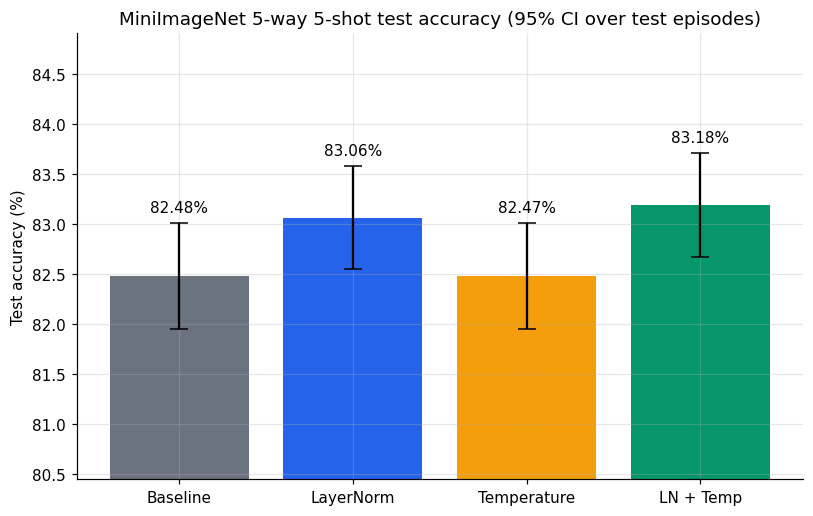

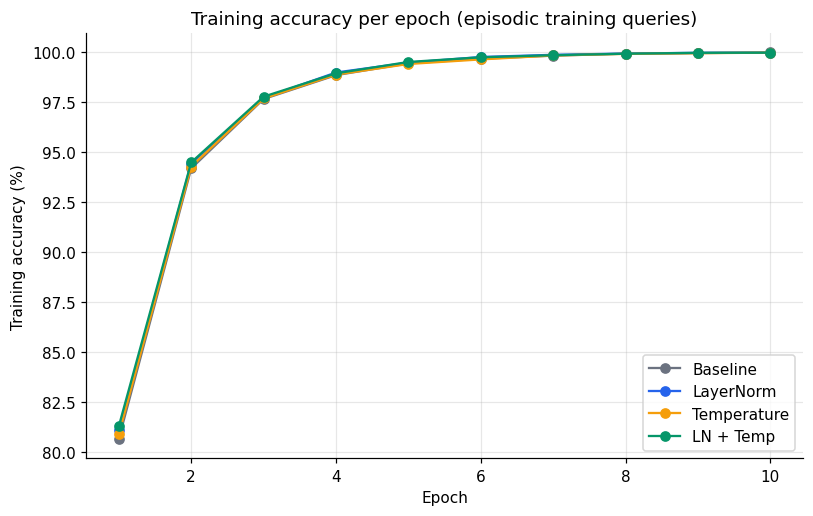

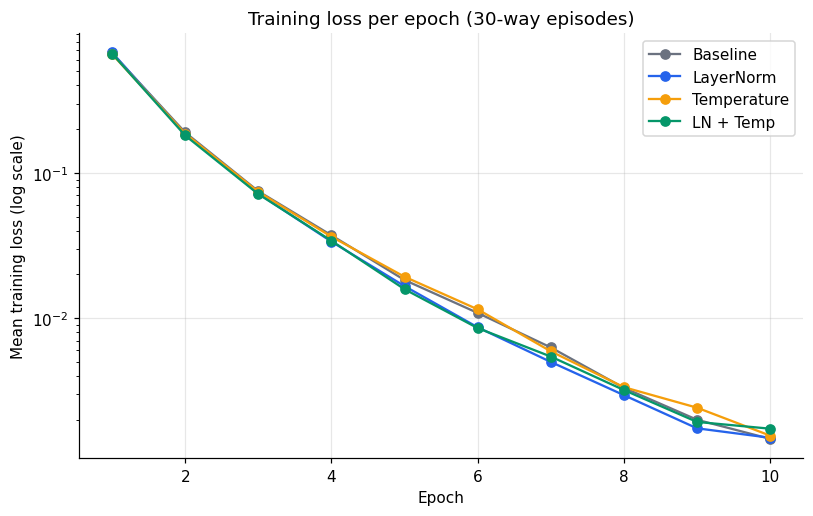

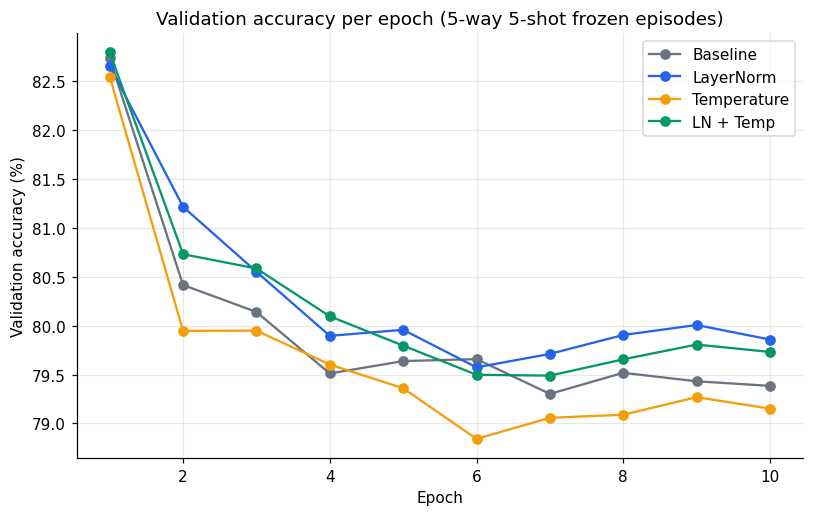

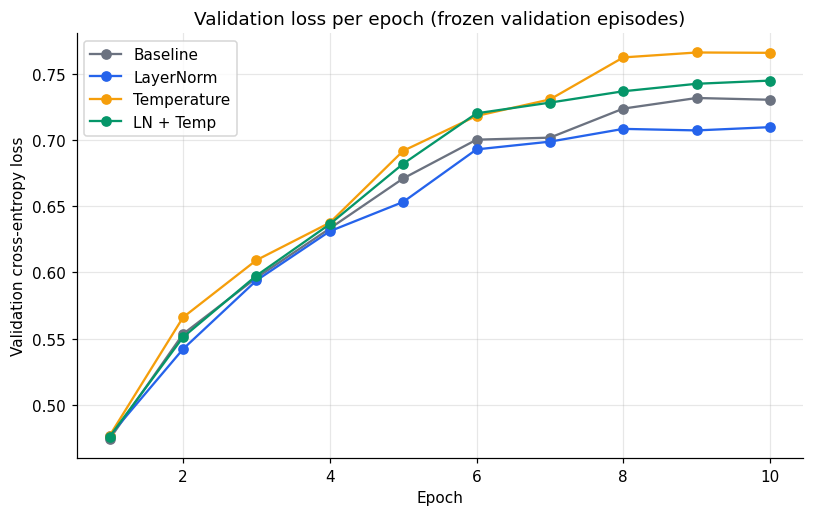

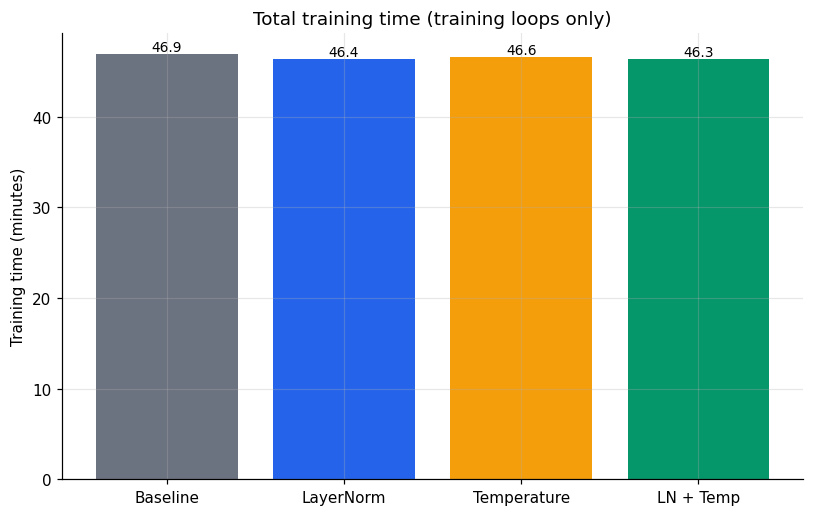

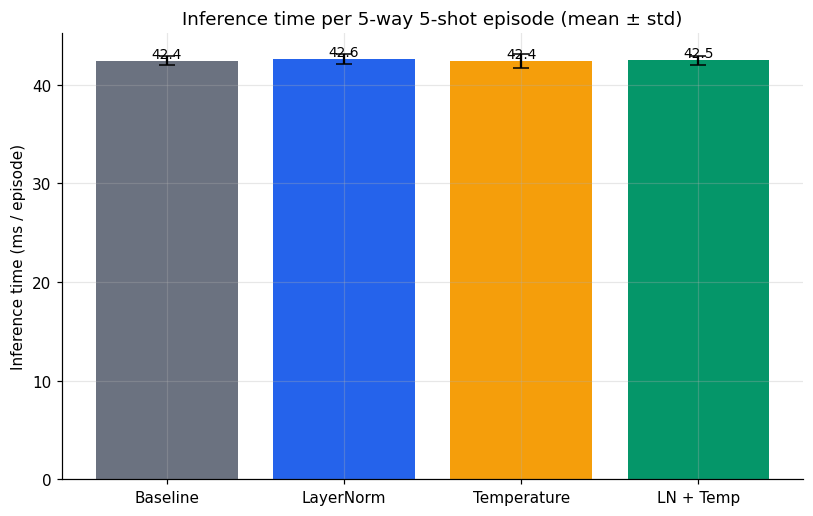

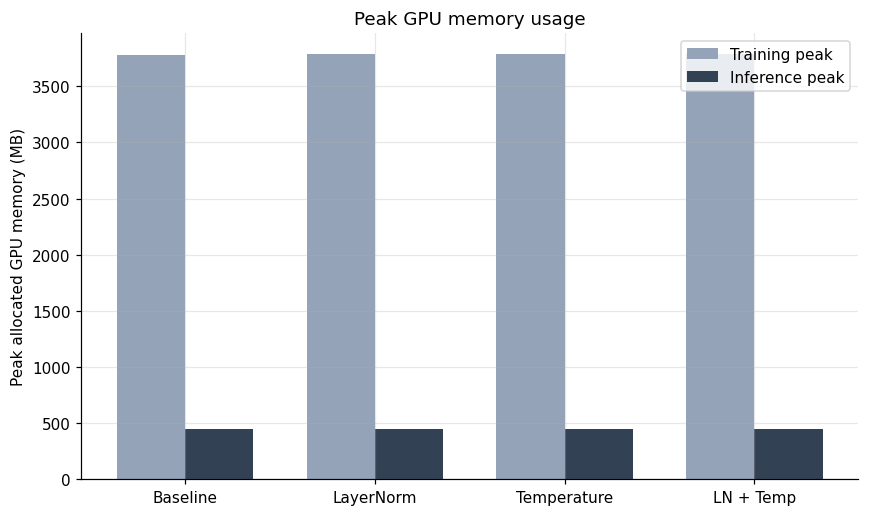

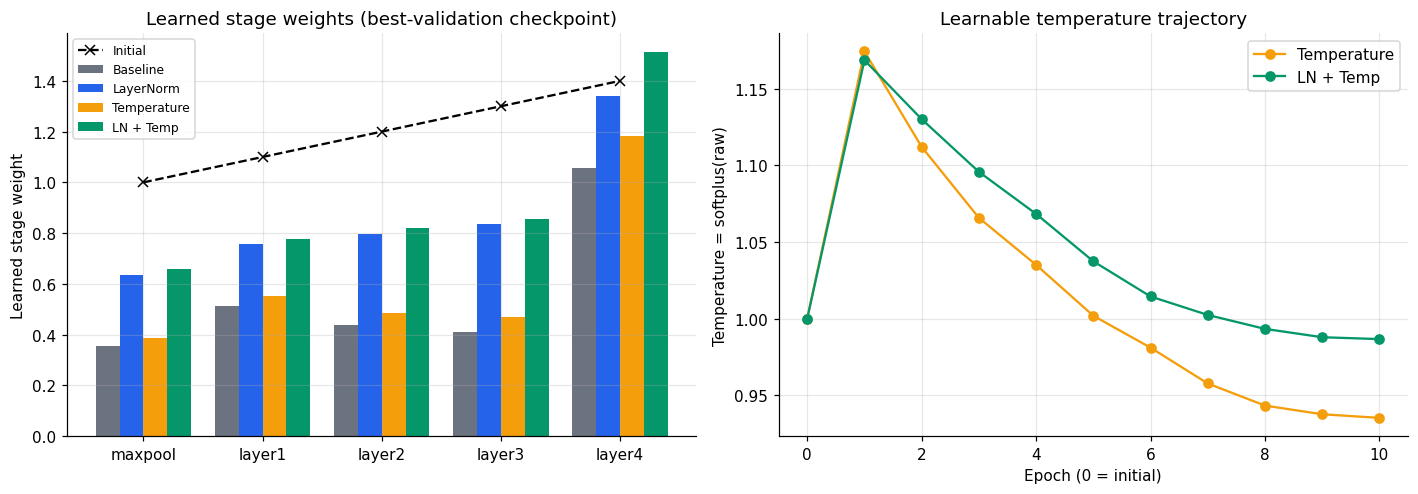

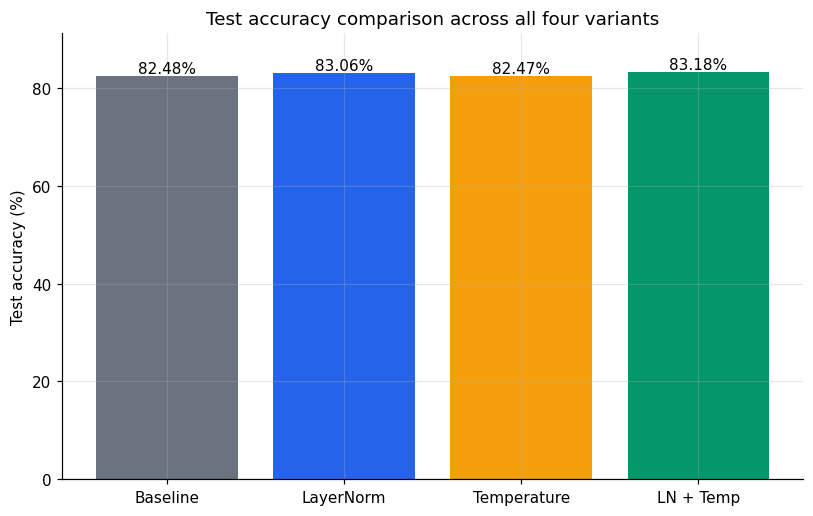

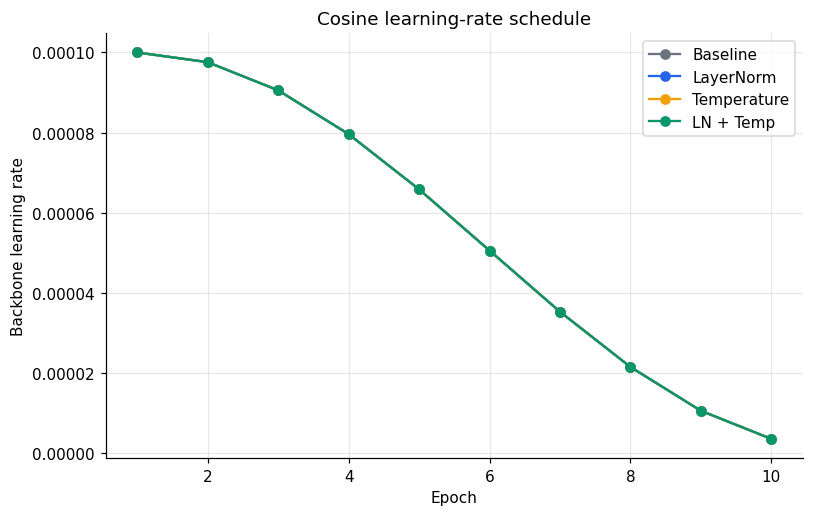

Saved plots: ['10_four_variant_accuracy_comparison.png', '11_learning_rate_trajectory.png', '1_test_accuracy_ci.png', '2_training_accuracy_per_epoch.png', '3_training_loss_per_epoch.png', '4_validation_accuracy_per_epoch.png', '5_validation_loss_per_epoch.png', '6_training_time.png', '7_inference_time.png', '8_gpu_memory.png', '9_learned_weights_and_temperature.png']


In [11]:
COLORS = {'baseline': '#6b7280', 'layernorm': '#2563eb', 'temperature': '#f59e0b', 'ln_temp': '#059669'}
keys = [v['key'] for v in VARIANTS]
shorts = [v['short'] for v in VARIANTS]
cols = [COLORS[k] for k in keys]
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False})

def save_plot(fig, filename):
    plt.tight_layout()
    fig.savefig(PLOTS_DIR / filename, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

# 1) Test accuracy with 95% CI (existing plot retained)
fig, ax = plt.subplots(figsize=(7.5, 4.8))
accs = [RESULTS[k]['test_acc'] for k in keys]
cis = [RESULTS[k]['test_ci95'] for k in keys]
ax.bar(range(4), accs, yerr=cis, capsize=6, color=cols)
for i, (a, c) in enumerate(zip(accs, cis)):
    ax.text(i, a + c + 0.08, f'{a:.2f}%', ha='center', va='bottom', fontsize=10)
ax.set_xticks(range(4)); ax.set_xticklabels(shorts)
ax.set_ylim(min(a - c for a, c in zip(accs, cis)) - 1.5,
            max(a + c for a, c in zip(accs, cis)) + 1.2)
ax.set_ylabel('Test accuracy (%)')
ax.set_title('MiniImageNet 5-way 5-shot test accuracy (95% CI over test episodes)')
save_plot(fig, '1_test_accuracy_ci.png')

# 2) Training accuracy per epoch (new)
fig, ax = plt.subplots(figsize=(7.5, 4.8))
for k, label, color in zip(keys, shorts, cols):
    h = pd.DataFrame(RESULTS[k]['history'])
    ax.plot(h['epoch'], h['train_acc'], marker='o', label=label, color=color)
ax.set_xlabel('Epoch'); ax.set_ylabel('Training accuracy (%)')
ax.set_title('Training accuracy per epoch (episodic training queries)')
ax.legend()
save_plot(fig, '2_training_accuracy_per_epoch.png')

# 3) Training loss per epoch (existing plot retained)
fig, ax = plt.subplots(figsize=(7.5, 4.8))
for k, label, color in zip(keys, shorts, cols):
    h = pd.DataFrame(RESULTS[k]['history'])
    ax.plot(h['epoch'], h['train_loss'], marker='o', label=label, color=color)
ax.set_yscale('log')
ax.set_xlabel('Epoch'); ax.set_ylabel('Mean training loss (log scale)')
ax.set_title('Training loss per epoch (30-way episodes)')
ax.legend()
save_plot(fig, '3_training_loss_per_epoch.png')

# 4) Validation accuracy per epoch (existing plot retained)
fig, ax = plt.subplots(figsize=(7.5, 4.8))
for k, label, color in zip(keys, shorts, cols):
    h = pd.DataFrame(RESULTS[k]['history'])
    ax.plot(h['epoch'], h['val_acc'], marker='o', label=label, color=color)
ax.set_xlabel('Epoch'); ax.set_ylabel('Validation accuracy (%)')
ax.set_title('Validation accuracy per epoch (5-way 5-shot frozen episodes)')
ax.legend()
save_plot(fig, '4_validation_accuracy_per_epoch.png')

# 5) Validation loss per epoch (new)
fig, ax = plt.subplots(figsize=(7.5, 4.8))
for k, label, color in zip(keys, shorts, cols):
    h = pd.DataFrame(RESULTS[k]['history'])
    ax.plot(h['epoch'], h['val_loss'], marker='o', label=label, color=color)
ax.set_xlabel('Epoch'); ax.set_ylabel('Validation cross-entropy loss')
ax.set_title('Validation loss per epoch (frozen validation episodes)')
ax.legend()
save_plot(fig, '5_validation_loss_per_epoch.png')

# 6) Training time (separate efficiency plot)
fig, ax = plt.subplots(figsize=(7.5, 4.8))
train_minutes = [RESULTS[k]['train_time_sec'] / 60 for k in keys]
bars = ax.bar(range(4), train_minutes, color=cols)
for bar, value in zip(bars, train_minutes):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f'{value:.1f}',
            ha='center', va='bottom', fontsize=9)
ax.set_xticks(range(4)); ax.set_xticklabels(shorts)
ax.set_ylabel('Training time (minutes)')
ax.set_title('Total training time (training loops only)')
save_plot(fig, '6_training_time.png')

# 7) Inference time (separate efficiency plot)
fig, ax = plt.subplots(figsize=(7.5, 4.8))
infer_ms = [RESULTS[k]['infer_ms_mean'] for k in keys]
infer_std = [RESULTS[k]['infer_ms_std'] for k in keys]
bars = ax.bar(range(4), infer_ms, yerr=infer_std, capsize=5, color=cols)
for bar, value in zip(bars, infer_ms):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f'{value:.1f}',
            ha='center', va='bottom', fontsize=9)
ax.set_xticks(range(4)); ax.set_xticklabels(shorts)
ax.set_ylabel('Inference time (ms / episode)')
ax.set_title('Inference time per 5-way 5-shot episode (mean ± std)')
save_plot(fig, '7_inference_time.png')

# 8) GPU memory (separate efficiency plot)
fig, ax = plt.subplots(figsize=(8, 4.8))
x = np.arange(4); width = 0.36
train_mem = [RESULTS[k]['gpu_peak_train_alloc_mb'] for k in keys]
infer_mem = [RESULTS[k]['gpu_peak_infer_alloc_mb'] for k in keys]
ax.bar(x - width/2, train_mem, width, label='Training peak', color='#94a3b8')
ax.bar(x + width/2, infer_mem, width, label='Inference peak', color='#334155')
ax.set_xticks(x); ax.set_xticklabels(shorts)
ax.set_ylabel('Peak allocated GPU memory (MB)')
ax.set_title('Peak GPU memory usage')
ax.legend()
save_plot(fig, '8_gpu_memory.png')

# 9) Learned stage weights and temperature trajectory (existing plot retained)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
x = np.arange(len(STAGE_NODES)); width = 0.2
for j, (k, label, color) in enumerate(zip(keys, shorts, cols)):
    axes[0].bar(x + (j - 1.5) * width, RESULTS[k]['learned']['stage_weights'],
                width, label=label, color=color)
axes[0].plot(x, list(STAGE_WEIGHTS), 'k--', marker='x', label='Initial')
axes[0].set_xticks(x); axes[0].set_xticklabels(STAGE_NODES)
axes[0].set_ylabel('Learned stage weight')
axes[0].set_title('Learned stage weights (best-validation checkpoint)')
axes[0].legend(fontsize=8)
for k, label, color in zip(keys, shorts, cols):
    if RESULTS[k]['use_temperature']:
        h = pd.DataFrame(RESULTS[k]['history'])
        axes[1].plot([0] + h['epoch'].tolist(),
                     [TEMPERATURE_INIT] + h['temperature'].tolist(),
                     marker='o', label=label, color=color)
axes[1].set_xlabel('Epoch (0 = initial)')
axes[1].set_ylabel('Temperature = softplus(raw)')
axes[1].set_title('Learnable temperature trajectory')
axes[1].legend()
save_plot(fig, '9_learned_weights_and_temperature.png')

# 10) Direct bar comparison of all four variants' test accuracies (new)
fig, ax = plt.subplots(figsize=(7.5, 4.8))
bars = ax.bar(range(4), accs, color=cols)
for bar, value in zip(bars, accs):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
            f'{value:.2f}%', ha='center', va='bottom', fontsize=10)
ax.set_xticks(range(4)); ax.set_xticklabels(shorts)
ax.set_ylabel('Test accuracy (%)')
ax.set_title('Test accuracy comparison across all four variants')
ax.set_ylim(0, max(accs) + 8)
save_plot(fig, '10_four_variant_accuracy_comparison.png')

# 11) Additional diagnostic: learning-rate trajectory
fig, ax = plt.subplots(figsize=(7.5, 4.8))
for k, label, color in zip(keys, shorts, cols):
    h = pd.DataFrame(RESULTS[k]['history'])
    ax.plot(h['epoch'], h['lr_backbone'], marker='o', label=label, color=color)
ax.set_xlabel('Epoch'); ax.set_ylabel('Backbone learning rate')
ax.set_title('Cosine learning-rate schedule')
ax.legend()
save_plot(fig, '11_learning_rate_trajectory.png')

print('Saved plots:', sorted(p.name for p in PLOTS_DIR.glob('*.png')))

## 10. ZIP everything and trigger the download

In [12]:
ZIP_PATH = Path('/kaggle/working/msenet_ln_temperature_comparison.zip')
if ZIP_PATH.exists():
    ZIP_PATH.unlink()
BANNED = {'.pth', '.pt', '.ckpt', '.bin', '.safetensors'}
with zipfile.ZipFile(ZIP_PATH, 'w', zipfile.ZIP_DEFLATED) as zf:
    for f in sorted(RESULTS_DIR.rglob('*')):
        rel = f.relative_to(RESULTS_DIR)
        if f.is_file() and 'partial' not in rel.parts and f.suffix.lower() not in BANNED:
            zf.write(f, arcname=str(Path(RESULTS_DIR.name) / rel))
with zipfile.ZipFile(ZIP_PATH) as zf:
    for info in zf.infolist():
        print(f'{info.file_size / 1024:9.1f} KB  {info.filename}')
size_mb = ZIP_PATH.stat().st_size / 2**20
print(f'\nZIP ready: {ZIP_PATH}  ({size_mb:.2f} MB)')

print('\nFINAL SUMMARY (5-way 5-shot, MiniImageNet)')
display(summary_df[['Variant', 'Test acc 5w5s (%)', '95% CI (+/-)', 'Delta vs baseline (pp)', 'Train time total (min)',
                    'Inference (ms / episode)', 'Params total', 'Params trainable', 'Peak GPU mem train (MB)']].round(3))

# Clickable fallback link (also available in the notebook's Output tab) + automatic browser download
display(FileLink(os.path.relpath(ZIP_PATH, os.getcwd()), result_html_prefix='Download ZIP: '))
if size_mb < 15:
    b64 = base64.b64encode(ZIP_PATH.read_bytes()).decode('ascii')
    js = ("(function(){var b64='" + b64 + "';var bin=atob(b64);var arr=new Uint8Array(bin.length);"
          "for(var i=0;i<bin.length;i++){arr[i]=bin.charCodeAt(i);}"
          "var blob=new Blob([arr],{type:'application/zip'});var a=document.createElement('a');"
          "a.href=URL.createObjectURL(blob);a.download='" + ZIP_PATH.name + "';document.body.appendChild(a);a.click();"
          "setTimeout(function(){URL.revokeObjectURL(a.href);a.remove();},1500);})();")
    display(Javascript(js))
else:
    print('ZIP is large; use the link above or the Output tab.')

      0.7 KB  msenet_comparison_results/config_and_environment.csv
      1.5 KB  msenet_comparison_results/layernorm_summary.csv
      0.6 KB  msenet_comparison_results/learned_parameters.csv
    115.0 KB  msenet_comparison_results/learned_parameters.json
      0.4 KB  msenet_comparison_results/paired_vs_baseline.csv
      0.4 KB  msenet_comparison_results/paper_style_table.csv
     18.7 KB  msenet_comparison_results/per_episode_test_accuracy.csv
      5.8 KB  msenet_comparison_results/per_epoch_history.csv
     36.1 KB  msenet_comparison_results/plots/10_four_variant_accuracy_comparison.png
     62.9 KB  msenet_comparison_results/plots/11_learning_rate_trajectory.png
     52.4 KB  msenet_comparison_results/plots/1_test_accuracy_ci.png
     67.9 KB  msenet_comparison_results/plots/2_training_accuracy_per_epoch.png
     80.8 KB  msenet_comparison_results/plots/3_training_loss_per_epoch.png
    101.2 KB  msenet_comparison_results/plots/4_validation_accuracy_per_epoch.png
     88.8 KB  ms

,Variant,Test acc 5w5s (%),95% CI (+/-),Delta vs baseline (pp),Train time total (min),Inference (ms / episode),Params total,Params trainable,Peak GPU mem train (MB)
0,1. Baseline (unchanged),82.476,0.531,0.000,46.879,42.428,11618120,11618120,3780.056
1,2. LayerNorm only,83.060,0.516,0.584,46.418,42.557,11620168,11620168,3783.104
2,3. Learnable temperature only,82.473,0.531,-0.002,46.563,42.372,11618121,11618121,3782.920
3,4. LayerNorm + temperature,83.184,0.521,0.709,46.345,42.456,11620169,11620169,3783.106


/kaggle/working/msenet_ln_temperature_comparison.zip

<IPython.core.display.Javascript object>